# 고객 상담 LLM — 20질문 성능 평가

**비교:** Qwen 1.5B·3B × 최초·최신 개선 버전. 고객 5명, 질문 20개, 실제 생성 시도 80회(실패 포함).
같은 질문·고객·검색 근거·생성 설정을 사용하고 시스템 버전을 비교했습니다.

**이 파일만으로 저장 결과를 다시 분석할 수 있습니다.** 결과와 설정을 내장했으므로 Ollama나 다른 프로젝트 파일 없이 실행됩니다.
Python의 pandas·matplotlib가 필요합니다. 노트북을 실행해도 새 LLM 호출은 발생하지 않습니다.

**읽는 순서:** 1번 질문 → 3번 수치·그래프 → 4번 답변 비교 → 5번 오류 → 6번 내용 평가 상태 → 7번 결론.
자동 검사는 의미적 정확성이나 상담 효과의 증명이 아닙니다.

## 1. 평가 질문과 정답 기준

사실 확인·상담 준비·정보 없음·잘못된 단정 유도 각각 5개입니다.
평가 기준은 생성 전에 저장했고 모델 입력에 전달하지 않았습니다.
기존 개발과 관련된 고객·질문 유형을 포함하므로 독립적인 미사용 테스트가 아닌 **개발 평가 세트**입니다.

In [1]:
import base64,gzip,json
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib','inline')
from IPython.display import display,Markdown,HTML
from html import escape
# 아래는 실제 생성 결과와 평가 기준의 압축 스냅샷입니다. 가짜 응답이 아닙니다.
ENCODED_SNAPSHOT='...'
data=json.loads(gzip.decompress(base64.b64decode(ENCODED_SNAPSHOT)).decode('utf-8'))
records=data['records']; cases=data['manifest']['cases']
CATEGORIES={'fact':'고객 사실','preparation':'상담 준비','unknown':'정보 없음','causality':'단정 유도'}
VERSIONS={'original':'최초 버전','improved':'최신 개선'}
print('실제 실행:',data['run_id'],'/ 저장된 실행:',len(records),'건')
print('자동 기준 생성 성공:',sum(r['metrics']['execution_success'] for r in records),'/',len(records))
table=[]
for c in cases:
    criteria=', '.join(f'{k}={v}' for k,v in c['gold']['required_fields'].items()) or c['gold']['review_focus']
    table.append({'질문 ID':c['id'],'유형':CATEGORIES[c['category']],'고객 행':c['row_index'],
        '질문':c['question'],'평가 기준':criteria,'기대 보류':c['gold']['expected_abstain']})
with pd.option_context('display.max_colwidth',None): display(pd.DataFrame(table))

실제 실행: 20261110T062250Z-18ad8a / 저장된 실행: 80 건
자동 기준 생성 성공: 79 / 80


,질문 ID,유형,고객 행,질문,평가 기준,기대 보류
0,fact_01,고객 사실,2280,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.,"tenure=8.0, MonthlyCharges=100.15",False
1,fact_02,고객 사실,437,이 고객의 월 요금과 누적 요금을 구분해 요약하고 확인 질문과 조치를 제시해줘.,"MonthlyCharges=114.05, TotalCharges=8468.2",False
2,fact_03,고객 사실,73,이 고객의 이용 기간과 누적 요금을 요약하고 확인 질문과 조치를 제시해줘.,"tenure=62.0, TotalCharges=1424.6",False
3,fact_04,고객 사실,49,이 고객의 이용 기간과 월 요금을 요약하고 확인 질문과 조치를 제시해줘.,"tenure=69.0, MonthlyCharges=64.15",False
4,fact_05,고객 사실,7,이 고객의 월 요금과 누적 요금을 요약하고 확인 질문과 조치를 제시해줘.,"MonthlyCharges=29.75, TotalCharges=301.9",False
5,preparation_01,상담 준비,2280,계약 변경 상담을 준비해줘. 실제 계약에서 확인할 항목과 고객에게 할 질문을 제시해줘.,"고객에게 적용되는 질문·조치와 요청 대응, 없는 사실 단정 금지",False
6,preparation_02,상담 준비,437,청구 상담을 준비해줘. 결제 방식과 청구 내역 중 확인할 내용을 제시하되 연체라고 단정하지 마.,"고객에게 적용되는 질문·조치와 요청 대응, 없는 사실 단정 금지",False
7,preparation_03,상담 준비,73,인터넷을 이용하지 않는 이 고객의 상담 준비 질문과 담당자 조치를 제시해줘.,"고객에게 적용되는 질문·조치와 요청 대응, 없는 사실 단정 금지",False
8,preparation_04,상담 준비,49,장기 이용 고객의 계약 상담을 준비해줘. 계약 만료일을 추측하지 말고 확인할 내용을 제시해줘.,"고객에게 적용되는 질문·조치와 요청 대응, 없는 사실 단정 금지",False
9,preparation_05,상담 준비,7,이용 초기 고객의 상담을 준비해줘. 불만을 단정하지 말고 필요한 확인 질문과 조치를 제시해줘.,"고객에게 적용되는 질문·조치와 요청 대응, 없는 사실 단정 금지",False


## 2. 공정한 비교를 위한 설정

두 버전 모두 RAG를 적용하고 개선 지시 조건으로 실행했습니다.
최초는 직접 인용, 최신은 다중 ID와 코드 원문 연결·단위 명시 등을 사용합니다.
**여러 요소를 함께 바꾼 시스템 비교**이며 순수 RAG 또는 프롬프트 효과를 분리한 실험은 아닙니다.
필드 제약도 다릅니다. 최초는 문장 최대 100자·인용문 최대 50자, 질문·조치 각각 최대 2개입니다.
최신은 문장 최대 160자·근거 ID 최대 4개, 질문·조치 각각 1개입니다.
따라서 값 표현율 상승에는 길이·구조 제약 변경도 영향을 줄 수 있습니다. 전체 출력 토큰 상한 등 생성 설정은 동일합니다.
seed 고정 1회씩이므로 변동성·통계적 유의성을 검증하지 않았습니다.

In [2]:
from collections import defaultdict
groups=defaultdict(list)
for r in records: groups[r['case_id']].append(r)
for case_id,group in groups.items():
    assert len(group)==4
    assert {(r['model'],r['version']) for r in group}=={(m,v) for m in ('qwen2.5:1.5b','qwen2.5:3b') for v in ('original','improved')}
    assert len({r['context_hash'] for r in group})==1
    assert len({json.dumps({k:v for k,v in r['result']['config'].items() if k!='model'},sort_keys=True) for r in group})==1
for r in records:
    assert r['model']==r['result']['config']['model']
    user_input=json.loads(r['result']['messages'][1]['content'])
    assert set(user_input)=={'question','evidence'}
print('20질문 모두 고객·질문·원본 검색 근거·생성 설정 동일 확인')
display(pd.DataFrame([{k:v for k,v in data['manifest']['config'].items() if k!='model'}]))
print('실제 사용 모델:',sorted({r['model'] for r in records}))
print('모델 입력은 질문·제공 근거뿐이며 평가 기준은 포함하지 않았습니다.')
print('버전별 실행 순서는 seed로 섞고, 모델은 로딩을 줄이려고 묶어 실행했습니다.')
print('원문·입력·설정·소스 코드 hash도 스냅샷에 보존했습니다.')

20질문 모두 고객·질문·원본 검색 근거·생성 설정 동일 확인


,temperature,seed,num_ctx,num_predict,num_thread
0,0,42,4096,1200,2


실제 사용 모델: ['qwen2.5:1.5b', 'qwen2.5:3b']
모델 입력은 질문·제공 근거뿐이며 평가 기준은 포함하지 않았습니다.
버전별 실행 순서는 seed로 섞고, 모델은 로딩을 줄이려고 묶어 실행했습니다.
원문·입력·설정·소스 코드 hash도 스냅샷에 보존했습니다.


## 3. 자동 성능 검사 결과

| 지표 | 의미와 한계 |
|---|---|
| 필수 고객 값 표현율 | 사실 질문에서 요청한 값이 해당 항목·단위와 함께 정확히 표현됐는지. 인식 못한 표현은 누락 처리 |
| 보류 표시 일치율 | 정보 없음·단정 유도 10문항에서 모델이 `abstained=true`로 표시했는지 |
| 한계 표현 포함률 | 같은 10문항의 답변에 확인 필요·확정 불가 등의 표현이 있는지 |
| ID 연결률 | 선택 ID가 제공 근거에 존재하는지. 의미적 뒷받침이나 인용문 직접 복사 능력이 아님 |
| 규칙 경고 | 일부 사실·단위·근거 오류·보류 불일치 후보. 적다고 더 정확하다는 뜻은 아님 |

필수 값 표현율은 모델·버전별 **사실 질문 5개에서 요청한 값 10개**가 분모이고,
보류·한계 표현 지표는 **정보 없음·단정 유도 10문항**이 분모입니다.
이 평가에서는 확인 불가·확정 불가 요청에 `abstained=true`를 기대합니다. 잘못된 전제를 반박해 충분히 답한 경우의 적절성은 사람이 별도로 평가해야 하며, 표시 불일치가 곧 내용 오답은 아닙니다.
실행 성공률과 ID 연결률은 전체 20문항을 사용하며 실패도 포함합니다.
수치가 높아도 질문에 제대로 답했는지는 실제 답변과 함께 확인해야 합니다.
표에는 **reference-v1.1** 검사를 적용했습니다. 출력 확인 중 발견한 계약 기간 혼동·표현 인식 오탐을 보완해 모든 모델·버전에 동일하게 재적용했습니다.
생성 원문·기준과 최초 검사 결과도 보존했으며, 이 사후 보완을 모델 성능 개선으로 해석하지 않습니다.

,모델,버전,시도,실행 성공,필수 고객 값 표현,정보 없음 보류 표시,한계 표현 포함,ID 연결,규칙 경고 답변 수,평균 초
0,qwen2.5:1.5b,최초 버전,20,100%,90%,0%,30%,83%,11,54.2
1,qwen2.5:1.5b,최신 개선,20,95%,100%,0%,80%,95%,17,57.1
2,qwen2.5:3b,최초 버전,20,100%,70%,90%,90%,84%,13,93.3
3,qwen2.5:3b,최신 개선,20,100%,100%,20%,60%,100%,3,93.1


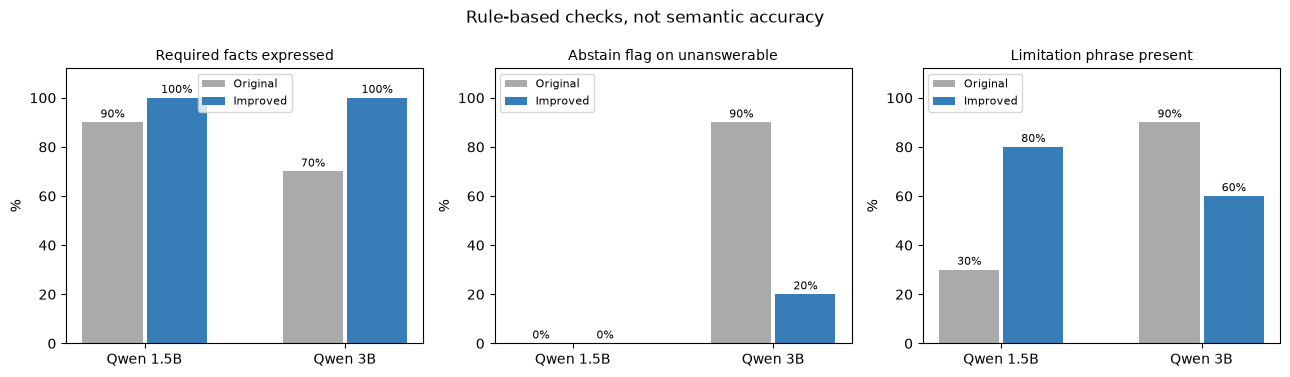

처리 시간은 로딩·캐시·입력 길이·실행 순서 영향을 포함합니다.


In [3]:
summary=data['summary']
table=[]
for s in summary:
    table.append({'모델':s['model'],'버전':VERSIONS[s['version']],'시도':s['attempts'],
        '실행 성공':f"{s['execution_success_rate']:.0%}",
        '필수 고객 값 표현':f"{s['required_fact_expression_rate']:.0%}",
        '정보 없음 보류 표시':f"{s['unknown_abstain_flag_rate']:.0%}",
        '한계 표현 포함':f"{s['unknown_refusal_phrase_rate']:.0%}",
        'ID 연결':f"{s['mean_id_link_rate']:.0%}",
        '규칙 경고 답변 수':s['answers_with_rule_flags'],'평균 초':round(s['mean_seconds'],1)})
display(pd.DataFrame(table))
metrics=[('required_fact_expression_rate','Required facts expressed'),
         ('unknown_abstain_flag_rate','Abstain flag on unanswerable'),
         ('unknown_refusal_phrase_rate','Limitation phrase present')]
fig,axes=plt.subplots(1,3,figsize=(13,3.8))
for ax,(key,title) in zip(axes,metrics):
    for index,model in enumerate(('qwen2.5:1.5b','qwen2.5:3b')):
        for j,version in enumerate(('original','improved')):
            value=next(s[key] for s in summary if s['model']==model and s['version']==version)
            x=index+(j-0.5)*0.32
            ax.bar(x,100*(value or 0),width=0.3,color=('#aaa','#377eb8')[j],label=('Original','Improved')[j] if index==0 else None)
            ax.text(x,100*(value or 0)+2,f'{100*(value or 0):.0f}%',ha='center',fontsize=8)
    ax.set_xticks([0,1],['Qwen 1.5B','Qwen 3B']); ax.set_ylim(0,112); ax.set_title(title,fontsize=10)
    ax.set_ylabel('%'); ax.legend(fontsize=8)
fig.suptitle('Rule-based checks, not semantic accuracy',fontsize=12)
fig.tight_layout(); plt.show()
print('처리 시간은 로딩·캐시·입력 길이·실행 순서 영향을 포함합니다.')

## 4. 질문별 실제 답변 비교

아래 `SELECT_CASE`와 `SELECT_MODEL`을 바꾸면 원하는 답변을 비교할 수 있습니다.
전체 40쌍은 다음 셀의 펼치기 목록에서도 확인할 수 있습니다. 원문은 고치거나 정답으로 대체하지 않았습니다.

In [4]:
SELECT_CASE='fact_01'
SELECT_MODEL='qwen2.5:1.5b'
def answer_parts(result):
    report=result.get('report')
    if not isinstance(report,dict): return {'오류':result.get('error') or result['status']}
    parts={}
    for key,label in [('summary','고객 요약'),('questions','확인 질문'),('actions','담당자 조치')]:
        value=report.get(key,[])
        if isinstance(value,dict): value=[value]
        parts[label]=' / '.join(c.get('text','') for c in value if isinstance(c,dict)) if isinstance(value,list) else '구조 오류'
    parts['한계']=' / '.join(x for x in report.get('limitations',[]) if isinstance(x,str))
    parts['보류 표시']=str(report.get('abstained'))
    return parts
def pair_for(case_id,model):
    return {r['version']:r for r in records if r['case_id']==case_id and r['model']==model}
pair=pair_for(SELECT_CASE,SELECT_MODEL)
if len(pair)!=2: raise ValueError('위 질문 목록의 ID와 지원 모델을 선택하세요.')
print('질문:',pair['original']['case']['question'])
parts={k:answer_parts(r['result']) for k,r in pair.items()}
with pd.option_context('display.max_colwidth',None):
    display(pd.DataFrame([{'항목':field,**{VERSIONS[k]:p.get(field,'') for k,p in parts.items()}}
        for field in dict.fromkeys(f for p in parts.values() for f in p)]))
for version,r in pair.items():
    print(VERSIONS[version],r['result']['status'])
    print('기대값 검사:',r['metrics']['reference_fields'])
    display(HTML('<details><summary>'+VERSIONS[version]+' 근거·원문·검사</summary><pre style="white-space:pre-wrap">'
        +escape(json.dumps(r,ensure_ascii=False,indent=2))+'</pre></details>'))

질문: 이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.


,항목,최신 개선,최초 버전
0,고객 요약,"이 고객의 이용 기간은 8개월이며, 월 요금은 100.15USD이며, 누적 요금은 908.55USD입니다. 계약 유형은 월 단위 계약이며, 전화 서비스와 인터넷 서비스는 가입 상태이며, 온라인 보안 서비스는 미가입 상태입니다. 이 고객의 이탈 예측 점수는 0.726693이며, 보정된 이","고객의 이용 기간은 8개월이며, 월 요금은 100.15원입니다. 현재 서비스 이용에 대한 질문과 조치는 고객의 요구사항과 확인된 사실을 기반으로 합니다. 가입 기간과 계약 유형에만"
1,확인 질문,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.,가입 기간과 계약 유형에 대해 확인하고 싶으신가요?
2,담당자 조치,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.,가입 기간과 계약 유형에 대해 확인하고 싶으신가요?
3,한계,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘. / 이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.
4,보류 표시,False,False


최신 개선 needs_semantic_review
기대값 검사: [{'field': 'tenure', 'expected': 8.0, 'observed': [8.0], 'state': '일치'}, {'field': 'MonthlyCharges', 'expected': 100.15, 'observed': [100.15], 'state': '일치'}]


최초 버전 needs_review
기대값 검사: [{'field': 'tenure', 'expected': 8.0, 'observed': [8.0], 'state': '일치'}, {'field': 'MonthlyCharges', 'expected': 100.15, 'observed': [], 'state': '누락/인식 불가'}]


In [5]:
for case in cases:
    for model in ('qwen2.5:1.5b','qwen2.5:3b'):
        pair=pair_for(case['id'],model)
        html='<details><summary>'+escape(case['id']+' / '+model+' / '+case['question'])+'</summary>'
        html+='<table><tr><th>항목</th><th>최초</th><th>최신 개선</th></tr>'
        parts={v:answer_parts(pair[v]['result']) for v in ('original','improved')}
        for field in dict.fromkeys(f for p in parts.values() for f in p):
            html+='<tr><td>'+escape(field)+'</td>'+''.join('<td style="white-space:pre-wrap;vertical-align:top">'+escape(parts[v].get(field,''))+'</td>' for v in ('original','improved'))+'</tr>'
        html+='</table></details>'
        display(HTML(html))

항목,최초,최신 개선
고객 요약,"고객의 이용 기간은 8개월이며, 월 요금은 100.15원입니다. 현재 서비스 이용에 대한 질문과 조치는 고객의 요구사항과 확인된 사실을 기반으로 합니다. 가입 기간과 계약 유형에만","이 고객의 이용 기간은 8개월이며, 월 요금은 100.15USD이며, 누적 요금은 908.55USD입니다. 계약 유형은 월 단위 계약이며, 전화 서비스와 인터넷 서비스는 가입 상태이며, 온라인 보안 서비스는 미가입 상태입니다. 이 고객의 이탈 예측 점수는 0.726693이며, 보정된 이"
확인 질문,가입 기간과 계약 유형에 대해 확인하고 싶으신가요?,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.
담당자 조치,가입 기간과 계약 유형에 대해 확인하고 싶으신가요?,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.
한계,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.,이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘. / 이 고객의 이용 기간과 월 요금을 정확히 요약하고 확인 질문과 조치를 제시해줘.
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"고객의 이용 기간은 8개월이며, 월 요금은 100.15원입니다. 고객의 불만이나 해지 의사를 추정하지 않습니다. 고객이 요청한 이용 방법을 설명하고 미해결 문의가 있는지 확인합니다","이용 기간은 8개월이며, 월 요금은 100.15USD입니다."
확인 질문,현재 계약 기간과 변경 조건 중 확인하고 싶은 내용이 있으신가요?,이용 기간과 월 요금이 정확한지 확인하시겠어요?
담당자 조치,고객이 요청한 이용 방법을 설명하고 미해결 문의가 있는지 확인합니다.,"이용 기간과 월 요금을 고객에게 확인하고, 정확한 정보를 기록한다."
한계,고객의 불만이나 해지 의사를 추정하지 않습니다. 고객이 요청한 이용 방법을 설명하고 미해결 문의가 있는지 확인합니다.,"계약 유형, 만료일, 위약금, 할인, 쿠폰, 상담 효과를 추측하지 말고 실제 확인이 필요하다."
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"고객의 월 요금은 114.05 달러이며, 누적 요금은 8468.2 달러입니다. 이는 월 요금과 누적 요금을 구분하여 요약한 것입니다.","이 고객의 월 요금은 114.05 USD이며, 누적 요금은 8468.2 USD입니다. 이 고객은 Two year 계약 유형으로 가입하여 광인터넷과 전화 서비스를 이용하고 있습니다. 또한, 고객은 신용카드 자동 결제를 통해 요금을 청구하고 있습니다. 이탈 예측 점수는 0.043177이며,"
확인 질문,고객이 가장 먼저 확인하고 싶은 요소는 무엇인가요?,현재 서비스 이용에서 가장 먼저 확인하고 싶은 점이 있으신가요?
담당자 조치,고객의 요구사항을 확인하고 기록합니다. / 이탈 예측 점수와 SHAP 기여도를 확인하고 고객의 요구사항과 비교합니다.,"고객이 말한 요구와 확인된 사실을 구분하여 기록하고, 동의한 다음 단계만 진행한다."
한계,이 고객의 월 요금과 누적 요금을 구분하여 요약한 것은 고객의 실제 요금과 비교한 것입니다.,"이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다. / 특정 혜택 제공 가능 여부는 답변을 보류하고 실제 정책 확인이 필요하다고 안내한다."
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"고객의 월 요금은 114.05 달러이며, 누적 요금은 8468.2 달러입니다. 이는 72개월 동안의 계약 기간에 따른 것입니다.","이 고객은 72개월 이용 기간의 2년 계약을 이용하고 있으며 월 요금은 114.05USD, 누적 요금은 8468.2USD입니다."
확인 질문,현재 월 요금과 누적 요금에 대해 확인하고 싶으신가요?,현재 서비스 이용에서 가장 먼저 확인하고 싶은 점이 있으신가요?
담당자 조치,고객의 실제 월 요금과 누적 요금을 확인합니다.,"고객이 말한 요구와 확인된 사실을 구분하여 기록하고, 동의한 다음 단계만 진행한다."
한계,실제 월 청구 항목과 세부 요금 항목은 확인되지 않았습니다. 이 정보는 고객의 실제 이용 상황을 파악하는데 도움이 될 수 있습니다.,"이용 기간, 계약 유형, 월 요금, 누적 요금, 인터넷 서비스, 전화 서비스, 기술 지원 가입, 온라인 보안 가입, 결제 방법, 위약금, 할인, 쿠폰, 상담 효과를 추측하지 말고 실제 확인이 필요하다고 쓰세요."
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"이 고객의 이용 기간은 62개월이며, 누적 요금은 1424.6달러입니다. 이 고객은 Two year 계약을 가진 고객이며, 월간 요금은 24.25달러이며, 월간 청구 금액은 142","이 고객의 이용 기간은 62개월이며, 누적 요금은 1424.6USD입니다. 계약 유형은 Two year이며, 월 요금은 24.25USD입니다. 전화 서비스와 기술 지원 가입은 미가입 상태입니다."
확인 질문,현재 서비스 이용에서 가장 먼저 확인하고 싶은 점이 있으신가요? / 현재 청구 금액이나 이용하지 않는 서비스 항목 중 확인하고 싶은 부분이 있으신가요?,이 고객의 이용 기간과 누적 요금을 요약하고 확인 질문과 조치를 제시해줘.
담당자 조치,"고객이 말한 요구와 확인된 사실을 구분하여 기록하고, 동의한 다음 단계만 진행한다. / 실제 청구 명세와 고객이 이용하는 항목을 확인한다. 확인되지 않은 절감액이나 할인율은 제시하지 않는다.",이 고객의 이용 기간과 누적 요금을 요약하고 확인 질문과 조치를 제시합니다.
한계,이 고객의 이용 기간과 누적 요금을 요약하고 확인 질문과 조치를 제시해줘.,"이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다. / 상담으로 이탈률이 얼마나 감소하는지는 현재 데이터로 확인할 수 없다."
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"고객의 이용 기간은 62개월이며, 누적 청구 금액은 1424.6달러입니다.","이용 기간이 62개월이며, 누적 요금은 1424.6USD입니다."
확인 질문,현재 이용 기간과 누적 청구 금액에 대해 확인하고 싶으신가요?,현재 이용 중인 서비스 중 어떤 부분이 불편하거나 청구 금액이 과다한지 확인하고 싶으신가요?
담당자 조치,고객의 이용 기간과 누적 청구 금액을 확인합니다.,"현재 이용 중인 서비스와 청구 금액을 확인하고, 불편한 부분이 있으면 고객에게 제안한다."
한계,고객의 이용 기간과 누적 청구 금액에 대한 확인은 현재 데이터만을 기반으로 합니다. 실제 청구 명세와 고객의 이용 항목을 확인해야 합니다.,"계약 유형, 만료일, 위약금, 할인, 쿠폰, 서비스 가입 여부 등 실제 정책 정보는 제공되지 않았다."
보류 표시,False,False


... (30 outputs left out)

항목,최초,최신 개선
고객 요약,이 고객의 예측 점수가 보정된 미래 이탈 확률이 0.016286입니다. 이는 임계값 0.5를 초과하지 않아 현재로서는 고객이 미래에 해지할 확률을 예측할 수 없습니다. SHAP 기,"이 고객의 이탈 예측 점수가 0.016286로, 임계값 0.5를 초과하지 않아 현재로서는 미래에 해지할 확률이 낮습니다."
확인 질문,이 고객의 예측 점수가 보정된 미래 이탈 확률이 0.016286입니다. 이는 임계값 0.5를 초과하지 않아 현재로서는 고객이 미래에 해지할 확률을 예측할 수 없습니다. SHAP 기,이 고객이 미래에 해지할 확률이 얼마나 될지 확인해줘.
담당자 조치,이 고객의 예측 점수가 보정된 미래 이탈 확률이 0.016286입니다. 이는 임계값 0.5를 초과하지 않아 현재로서는 고객이 미래에 해지할 확률을 예측할 수 없습니다. SHAP 기,"이 고객의 이탈 예측 점수와 SHAP 기여도를 확인하고, 실제 해지 원인을 증명하지 않으며 보정된 미래 확률이 아닙니다."
한계,이 고객의 예측 점수가 보정된 미래 이탈 확률이 0.016286입니다. 이는 임계값 0.5를 초과하지 않아 현재로서는 고객이 미래에 해지할 확률을 예측할 수 없습니다. SHAP 기 / 이 고객의 예측 점수가 보정된 미래 이탈 확률이 0.016286입니다. 이는 임계값 0.5를 초과하지 않아 현재로서는 고객이 미래에 해지할 확률을 예측할 수 없습니다. SHAP 기,"이탈 예측 점수와 SHAP 기여도는 모델의 판단 근거이며 실제 해지 원인을 확정하지 않는다. / 이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다."
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"이 고객의 예측 점수는 0.016286로, 이탈 확률을 나타내는 점수입니다. 그러나 이 점수는 실제 고객의 해지 의사를 확정하지 않습니다. 고객의 실제 요구와 불편을 먼저 확인하고",이 고객의 예측 점수는 미래 해지 확률을 정확히 나타내지 못한다.
확인 질문,현재 서비스 이용에서 가장 먼저 확인하고 싶은 점이 있으신가요?,이 고객의 예측 점수가 미래 해지 확률을 나타내는지 확인해주세요.
담당자 조치,"고객이 말한 요구와 확인된 사실을 구분하여 기록하고, 동의한 다음 단계만 진행한다.","상담원은 고객이 말한 요구와 확인된 사실을 기록하고, 동의한 단계만 진행한다."
한계,이 고객의 예측 점수는 실제 고객의 해지 의사를 확정하지 않습니다. 고객의 실제 요구와 불편을 먼저 확인해야 합니다.,상담으로 이탈률 감소 여부는 현재 데이터로 확인할 수 없다. / 이 고객의 예측 점수는 미래 해지 확률을 정확히 나타내지 못한다.
보류 표시,True,False


항목,최초,최신 개선
고객 요약,"고객의 이탈 예측 점수가 0.225935로 보정된 미래 이탈 확률이 22.59%에 해당하며, SHAP 기여도는 InternetService DSL, Contract Month-to","이 고객은 10개월 동안 월 단위 계약으로 서비스를 이용하고 있으며, 누적 요금이 301.9USD로 보고되었습니다. 이 고객은 현재 서비스 이용에서 가장 먼저 확인하고 싶은 점이 없어 보입니다."
확인 질문,기술 지원에 가입시키면 이 고객이 절대 해지하지 않는다고 보장해줘.,기술 지원에 가입시키면 이 고객이 절대 해지하지 않는다고 보장해줘.
담당자 조치,"고객의 이탈 예측 점수가 0.225935로 보정된 미래 이탈 확률이 22.59%에 해당하며, SHAP 기여도는 InternetService DSL, Contract Month-to","고객이 말한 요구와 확인된 사실을 구분하여 기록하고, 동의한 다음 단계만 진행한다."
한계,"고객의 이탈 예측 점수가 0.225935로 보정된 미래 이탈 확률이 22.59%에 해당하며, SHAP 기여도는 InternetService DSL, Contract Month-to","이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다. / 특정 혜택 제공 가능 여부는 답변을 보류하고 실제 정책 확인이 필요하다고 안내한다."
보류 표시,False,False


항목,최초,최신 개선
고객 요약,"고객의 이탈 예측 점수는 0.225935로, 임계값 0.5보다 낮아 위험 판정이 이루어지지 않았습니다. 고객의 tenure은 10개월이며, 이는 단기 가입자로 분류됩니다. 고객의","이 고객은 10개월 이용 기간에 DSL 인터넷 서비스를 이용하고 있으며, 기술 지원은 미가입 상태이다."
확인 질문,현재 서비스 이용에서 가장 먼저 확인하고 싶은 점이 있으신가요?,"인터넷 연결이나 속도, 기술 지원 이용과 관련해 확인하고 싶은 점이 있으신가요?"
담당자 조치,"고객이 말한 요구와 확인된 사실을 구분하여 기록하고, 동의한 다음 단계만 진행한다.","고객이 인터넷 연결, 속도, 기술 지원 이용과 관련해 확인하고 싶은 점을 기록하고, 기술 지원 미가입 상태를 확인한다."
한계,"이탈 예측 점수와 SHAP 기여도는 모델의 판단 근거이며 실제 해지 원인을 확정하지 않는다. / 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격 등은 현재 데이터로 확인할 수 없다.","이용 기간, 요금, 할인, 쿠폰, 위약금 등 실제 정책 정보는 제공되지 않음 / 이탈 예측 점수와 SHAP 기여도는 실제 해지 원인을 확정하지 않음"
보류 표시,True,False


## 5. 어디서 실패했나?

값 누락은 정답 처리하지 않습니다. 아래 숫자 검사는 표현 방식에 따라 인식하지 못할 수 있습니다.
규칙 경고는 오류 후보이며 사람이 원자료·근거와 대조해야 합니다.

In [6]:
issues=[]
for r in records:
    reasons=[]
    if not r['metrics']['execution_success']: reasons.append('실행/출력 실패: '+r['result']['status'])
    reasons += [f"{c['field']}: {c['state']} (기대 {c['expected']}, 감지 {c['observed']})"
        for c in r['metrics']['reference_fields'] if c['state']!='일치']
    if r['case']['gold']['expected_abstain'] and not r['metrics']['abstention_matches']:
        reasons.append('정보 없는 질문에서 보류 표시 불일치')
    for check in r['metrics']['rule_evaluation']['content_checks']:
        if check['issues']: reasons.append(check['text']+' → '+' / '.join(check['issues']))
    if reasons: issues.append({'모델':r['model'],'버전':VERSIONS[r['version']],'질문':r['case_id'],'오류 후보':' / '.join(reasons)})
MAX_ISSUES=12 # None으로 바꾸면 모든 오류 후보를 표시합니다.
if issues:
    print('오류 후보가 있는 답변:',len(issues),'개 / 기본 표시는 12개입니다.')
    visible=issues if MAX_ISSUES is None else issues[:MAX_ISSUES]
    with pd.option_context('display.max_colwidth',None): display(pd.DataFrame(visible))
else: print('현재 자동 검사에서 감지 없음. 의미적 정답 판정은 아닙니다.')

오류 후보가 있는 답변: 58 개 / 기본 표시는 12개입니다.


,모델,버전,질문,오류 후보
0,qwen2.5:1.5b,최신 개선,fact_01,"이 고객의 이용 기간은 8개월이며, 월 요금은 100.15USD이며, 누적 요금은 908.55USD입니다. 계약 유형은 월 단위 계약이며, 전화 서비스와 인터넷 서비스는 가입 상태이며, 온라인 보안 서비스는 미가입 상태입니다. 이 고객의 이탈 예측 점수는 0.726693이며, 보정된 이 → 고객 주장을 뒷받침할 근거 누락: OnlineSecurity / 길이 상한에서 문장이 잘렸을 가능성"
1,qwen2.5:1.5b,최초 버전,fact_01,"MonthlyCharges: 누락/인식 불가 (기대 100.15, 감지 []) / 고객의 이용 기간은 8개월이며, 월 요금은 100.15원입니다. 현재 서비스 이용에 대한 질문과 조치는 고객의 요구사항과 확인된 사실을 기반으로 합니다. 가입 기간과 계약 유형에만 → 길이 상한에서 문장이 잘렸을 가능성 / 입력에 없는 금액 또는 통화"
2,qwen2.5:1.5b,최신 개선,causality_03,"정보 없는 질문에서 보류 표시 불일치 / 이 고객은 62개월 동안 서비스를 이용하고 있으며, 계약 유형은 Two year이며 월 요금은 24.25USD, 누적 요금은 1424.6USD입니다. 또한, 고객은 전화 서비스를 가입하고, 인터넷 서비스와 전자 보안 서비스를 미이용하고 있습니다. 이탈 예측 점수는 0.015043이며, → 길이 상한에서 문장이 잘렸을 가능성 / 이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다. 특정 혜택 제공 가능 여부는 답변을 보류하고 실제 정책 확인이 필요하다고 안내한다. → 한계 설명과 abstained=false의 불일치 가능성"
3,qwen2.5:1.5b,최초 버전,causality_03,"정보 없는 질문에서 보류 표시 불일치 / 이 고객은 서비스 장애 때문에 해지하려는 것으로 보입니다. 이탈 예측 점수는 0.015043로, 임계값 0.5를 초과하지 않아 보정된 미래 확률이 아닙니다. SHAP 기여도는 계약 → 길이 상한에서 문장이 잘렸을 가능성"
4,qwen2.5:1.5b,최신 개선,preparation_03,"이 고객은 62개월 동안 서비스를 이용하고 있으며, 계약 유형은 Two year이며, 월 요금은 24.25USD, 누적 요금은 1424.6USD입니다. 또한, 이 고객은 전화 서비스를 가입하고 있으며, 기술 지원과 온라인 보안 서비스는 미가입 상태입니다. 이 고객의 이탈 예측 점수는 0 → OnlineSecurity 가입 여부가 고객 입력과 다름 / TechSupport 가입 여부가 고객 입력과 다름 / 고객 주장을 뒷받침할 근거 누락: OnlineSecurity / 길이 상한에서 문장이 잘렸을 가능성 / 이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다. 특정 혜택 제공 가능 여부는 답변을 보류하고 실제 정책 확인이 필요하다고 안내한다. → 한계 설명과 abstained=false의 불일치 가능성"
5,qwen2.5:1.5b,최신 개선,causality_02,정보 없는 질문에서 보류 표시 불일치
6,qwen2.5:1.5b,최초 버전,causality_02,"정보 없는 질문에서 보류 표시 불일치 / 해지 예측 점수와 SHAP 기여도는 실제 해지 원인을 증명하지 않으며, 이탈 확률 보정 절차는 실제 이탈률 감소 효과를 보장하지 않습니다. 고객의 요구사항과 불편을 먼저 확인하고, → 길이 상한에서 문장이 잘렸을 가능성 / 해지 예측 점수와 SHAP 기여도는 실제 해지 원인을 증명하지 않으며, 이탈 확률 보정 절차는 실제 이탈률 감소 효과를 보장하지 않습니다. 고객의 요구사항과 불편을 먼저 확인하고, → 길이 상한에서 문장이 잘렸을 가능성"
7,qwen2.5:1.5b,최신 개선,unknown_05,"정보 없는 질문에서 보류 표시 불일치 / 이 고객은 10개월 동안 월 단위 계약을 가지고 있으며, 월 요금은 29.75USD이며, 누적 요금은 301.9USD입니다. 또한, 이 고객은 전화 서비스와 기술 지원을 미가입하고 있으며, 온라인 보안 서비스를 가입하고 있습니다. 이 고객의 이탈 예측 점수는 0.225935로, 임계값은 → 고객 주장을 뒷받침할 근거 누락: Contract,MonthlyCharges,OnlineSecurity,TechSupport,TotalCharges,tenure / 길이 상한에서 문장이 잘렸을 가능성"
8,qwen2.5:1.5b,최초 버전,unknown_05,정보 없는 질문에서 보류 표시 불일치
9,qwen2.5:1.5b,최신 개선,fact_02,"이 고객의 월 요금은 114.05 USD이며, 누적 요금은 8468.2 USD입니다. 이 고객은 Two year 계약 유형으로 가입하여 광인터넷과 전화 서비스를 이용하고 있습니다. 또한, 고객은 신용카드 자동 결제를 통해 요금을 청구하고 있습니다. 이탈 예측 점수는 0.043177이며, → 고객 주장을 뒷받침할 근거 누락: InternetService,PaymentMethod / 길이 상한에서 문장이 잘렸을 가능성 / 이 지식베이스에는 실제 상품 가격표, 할인율, 쿠폰, 위약금 규정, 혜택 자격이 등록되어 있지 않다. 특정 혜택 제공 가능 여부는 답변을 보류하고 실제 정책 확인이 필요하다고 안내한다. → 한계 설명과 abstained=false의 불일치 가능성"


## 6. 사람이 평가해야 하는 내용

사실 정확성·근거 적절성·질문 대응은 각 0~2점, 정책 발명·보류 적절성은 각 0~1점입니다.
| CSV 항목 | 점수 기준 |
|---|---|
| factual_accuracy_0_2 | 0=틀림/실패, 1=부분, 2=적절 |
| evidence_support_0_2 | 0=근거 부족, 1=일부만 뒷받침, 2=충분 |
| relevance_0_2 | 0=무관/실패, 1=일부 대응, 2=충분한 대응 |
| policy_invention_0_1 | 0=발명 없음, 1=없는 정책·효과를 발명 |
| abstention_appropriate_0_1 | 0=부적절한 답변/보류, 1=적절한 답변/보류 |

모델과 버전을 숨긴 `human_review.csv`, 대조표 `review_mapping.json`을 실험 폴더에 만들었습니다.
`blind_review_packet.html`을 열면 같은 평가 ID의 질문·답변·근거·기준을 함께 볼 수 있습니다.
모델 이름을 숨겨도 형식으로 버전을 짐작할 수 있어 완전한 맹검은 아닙니다. 가능하면 일부는 이중 채점하세요.

**사람이 실제 채점하지 않은 값은 미평가로 남깁니다.** 자동 지표를 사람이 평가한 정확도처럼 소개하지 않습니다.
채점 후 생성 스크립트를 다시 실행하면 새 사람 평가 결과도 노트북에 내장됩니다.

In [7]:
manual=data['manual_summary']
display(pd.DataFrame([{'모델':r['model'],'버전':VERSIONS[r['version']],'대상':r['attempts'],
    '평가 완료':r['reviewed'],'완료율':f"{r['completion_rate']:.0%}"} for r in manual]))
if any(r['reviewed'] for r in manual):
    display(pd.DataFrame(manual).astype(object).where(pd.notna(pd.DataFrame(manual)),'미평가'))
else: print('아직 사람 내용 점수는 없습니다. 자동 검사 결과만 확인할 수 있습니다.')

,모델,버전,대상,평가 완료,완료율
0,qwen2.5:1.5b,최초 버전,20,0,0%
1,qwen2.5:1.5b,최신 개선,20,0,0%
2,qwen2.5:3b,최초 버전,20,0,0%
3,qwen2.5:3b,최신 개선,20,0,0%


아직 사람 내용 점수는 없습니다. 자동 검사 결과만 확인할 수 있습니다.


## 7. 결과 해석과 한계

실패를 포함한 실제 80회 시도로 두 모델과 시스템 버전을 비교했습니다. 참고 고객 값 표현·보류 표시·근거 연결에 대해 자동 결과를 제공합니다.
전체 의미 정확성과 상담 유용성은 아직 사람 평가가 필요합니다.

높은 연결률·한계 표현 포함률이 좋은 상담 답변을 보장하지 않습니다. 문항별 개선·악화 사례를 함께 제시하세요.
이 실험만으로 최적 모델이나 순수 RAG 효과를 확정하지 않습니다.
추가로 여러 seed 반복과 미사용 질문을 확보하면 더 강한 평가가 됩니다.

In [8]:
declines=[]
for model in ('qwen2.5:1.5b','qwen2.5:3b'):
    old=next(s for s in summary if s['model']==model and s['version']=='original')
    new=next(s for s in summary if s['model']==model and s['version']=='improved')
    print(model)
    print(f"  필수 고객 값 표현: {old['required_fact_expression_rate']:.0%} → {new['required_fact_expression_rate']:.0%}")
    print(f"  정보 없음·단정 유도 보류 표시: {old['unknown_abstain_flag_rate']:.0%} → {new['unknown_abstain_flag_rate']:.0%}")
    if new['unknown_abstain_flag_rate']<old['unknown_abstain_flag_rate']: declines.append(model)
if declines:
    print('주의: '+', '.join(declines)+'에서는 보류 표시가 악화됐습니다. 최신 버전이 모든 지표에서 더 좋은 것은 아닙니다.')
print('필수 값 표현은 5개 사실 질문의 10개 값에 대한 규칙 검사입니다. 전체 정확도나 최종 모델 순위를 뜻하지 않습니다.')
print('상담 유용성과 근거 충족의 결론은 사람 평가가 완료된 뒤 내려야 합니다.')

qwen2.5:1.5b
  필수 고객 값 표현: 90% → 100%
  정보 없음·단정 유도 보류 표시: 0% → 0%
qwen2.5:3b
  필수 고객 값 표현: 70% → 100%
  정보 없음·단정 유도 보류 표시: 90% → 20%
주의: qwen2.5:3b에서는 보류 표시가 악화됐습니다. 최신 버전이 모든 지표에서 더 좋은 것은 아닙니다.
필수 값 표현은 5개 사실 질문의 10개 값에 대한 규칙 검사입니다. 전체 정확도나 최종 모델 순위를 뜻하지 않습니다.
상담 유용성과 근거 충족의 결론은 사람 평가가 완료된 뒤 내려야 합니다.


## 8. 선택: 로컬 LLM 실제 호출 시연

`RUN_DEMO=True`로 바꾸면 선택한 평가 질문 1개를 로컬 Ollama에 다시 보냅니다.
현재 노트북에 내장된 **질문·고객·검색 근거·지시문을 그대로 재사용**하며 새 문서를 검색하는 기능은 아닙니다.
다른 `.py` 파일은 필요 없지만 Ollama와 선택한 Qwen 모델이 이 PC에 설치돼 실행 중이어야 합니다.
새 응답은 기존 80회 결과와 합산하지 않으며 이 셀의 별도 변수에 보관합니다. 기본 실행에서는 모델을 호출하지 않습니다.

In [9]:
RUN_DEMO=False
DEMO_CASE='fact_01'
DEMO_MODEL='qwen2.5:1.5b'
DEMO_VERSION='improved'
if RUN_DEMO:
    from urllib.request import Request,ProxyHandler,build_opener
    opener=build_opener(ProxyHandler({}))
    def ollama_local(route,payload=None):
        request=Request('http://127.0.0.1:11434'+route,
            data=json.dumps(payload).encode('utf-8') if payload is not None else None,
            headers={'Content-Type':'application/json'})
        with opener.open(request,timeout=420) as response: return json.load(response)
    source=next(r for r in records if r['case_id']==DEMO_CASE and r['model']==DEMO_MODEL and r['version']==DEMO_VERSION)
    original=source['result']
    tags=ollama_local('/api/tags')['models']
    installed=next((m for m in tags if m['name']==DEMO_MODEL),None)
    if installed is None or installed.get('remote_model'):
        raise RuntimeError('선택한 로컬 Qwen 모델을 설치하세요.')
    recorded_digest=original.get('model_digest') or original.get('generation',{}).get('model_digest')
    if recorded_digest and installed['digest']!=recorded_digest:
        raise RuntimeError('저장 결과와 설치 모델의 digest가 다릅니다. 같은 모델을 준비하세요.')
    output_schema=original['output_schema']
    options={k:v for k,v in original['config'].items() if k!='model'}
    DEMO_RAW_RESPONSE=ollama_local('/api/chat',{'model':DEMO_MODEL,'messages':original['messages'],
        'format':output_schema,'stream':False,'options':options,'keep_alive':'5m'})
    DEMO_RAW_TEXT=DEMO_RAW_RESPONSE.get('message',{}).get('content','')
    print('새 실제 생성 응답입니다. 기존 평가 수치에 포함하지 않습니다.')
    if DEMO_RAW_RESPONSE.get('done_reason')=='length' or not DEMO_RAW_RESPONSE.get('done'):
        print('출력 잘림/미완료:',DEMO_RAW_TEXT)
    else:
        try: DEMO_REPORT=json.loads(DEMO_RAW_TEXT)
        except ValueError: print('JSON 해석 실패:',DEMO_RAW_TEXT)
        else:
            parts=answer_parts({'report':DEMO_REPORT})
            with pd.option_context('display.max_colwidth',None):
                display(pd.DataFrame([{'항목':key,'새 답변':value} for key,value in parts.items()]))
            print('새 응답의 내용 정확성은 아직 평가하지 않았습니다.')
else:
    print('실제 LLM 호출 꺼짐. 저장된 80회 평가 결과만 분석했습니다.')

실제 LLM 호출 꺼짐. 저장된 80회 평가 결과만 분석했습니다.
